# 03 — Validation: did K-Means *rediscover* the periodic families?

**Verdict-up-front (computed below, no suspense):**
- At family granularity (18 groups) the answer is **NO — ARI ≈ 0.02** at the silhouette-chosen k.
- The coarse *block* level (s/p/d/f) shows **weak but persistent alignment** (ARI 0.14→0.24).
- Conclusion: physical-property space recovers chemistry's *continents*
  (light-nonmetals / transition-heavy / superheavy), while **families live in electron
  configuration — not in bulk properties** (the alkali family alone spans Li, 7 u, to Fr, 223 u).

Integrity rules honored in this notebook: clustering and k-selection have already happened
(notebook 02) — every ARI here is **validation only**; no k is re-tuned against labels.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import adjusted_rand_score

from data import load_elements
from study import build_feature_matrix, elbow_silhouette, fit_labels

df = load_elements()
X, feats = build_feature_matrix(df)
tab = elbow_silhouette(X)
k_star = int(tab.sil_mean.idxmax())
labeled = df.group_id.notna().to_numpy()
y_true = df.loc[labeled, "group_id"].astype(int).to_numpy()
print(f"k* = {k_star} (silhouette), labeled elements for ARI: {labeled.sum()}")

k* = 5 (silhouette), labeled elements for ARI: 90


## 1. ARI at the silhouette-chosen k (3 seeds)

ARI (Adjusted Rand Index) ≈ 0 ⇒ agreement no better than chance; ≈ 1 ⇒ perfect.

In [2]:
seed_scores = []
for seed in (0, 1, 2):
    labels, _, _ = fit_labels(X, k=k_star, seed=seed)
    seed_scores.append(adjusted_rand_score(y_true, labels[labeled]))
ari = pd.Series(seed_scores)
print(f"ARI@k*({k_star}) over labeled {labeled.sum()} elements:")
print(ari.round(4).rename("ARI").to_string())
print(f"mean ± std = {ari.mean():.4f} ± {ari.std():.4f}")
pd.DataFrame({"seed": [0, 1, 2], "ari": seed_scores}).to_csv(
    ROOT / "reports" / "tables" / "ari_summary.csv", index=False)
print(f"\nVERDICT: {'rediscovered' if ari.mean() > 0.5 else 'NOT rediscovered'} at family granularity.")

ARI@k*(5) over labeled 90 elements:
0    0.0164
1    0.0164
2    0.0164
mean ± std = 0.0164 ± 0.0000

VERDICT: NOT rediscovered at family granularity.


## 2. Why it fails *cheerfully* — the geometry argument

The alkali family spans **Li (7 u) → Fr (223 u)** — 32× in weight across five periods.
K-Means on physical properties cannot render one family from a set whose members are
physically five octaves apart; grouping by *bulk properties* produces size/recency
**continents** (light start-of-row, dense transition middle, superheavy tail) instead of
vertical columns. Chemistry picked its *columns* by valence configuration; our features
don't contain that.

## 3. The k=18 companion (validation-only run)

Forcing 18 clusters — the family count — as a *post-hoc* check (never used to select k):

ARI@k=18 (companion, seed 0): 0.0240  — still ≈ 0: 18 partitions of size-space ≠ 18 families


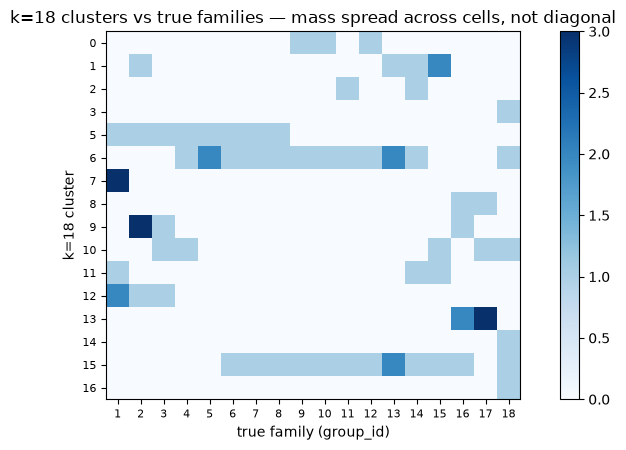

In [3]:
labels18, _, _ = fit_labels(X, k=18, seed=0)
ari18 = adjusted_rand_score(y_true, labels18[labeled])
print(f"ARI@k=18 (companion, seed 0): {ari18:.4f}  — still ≈ 0: 18 partitions of size-space ≠ 18 families")

ct = pd.crosstab(pd.Series(labels18, name="cluster")[labeled], pd.Series(y_true, name="family"))
fig, ax = plt.subplots(figsize=(8.6, 4.6))
im = ax.imshow(ct.values, cmap="Blues")
ax.set_xticks(range(len(ct.columns)), ct.columns, fontsize=8)
ax.set_yticks(range(len(ct.index)), ct.index, fontsize=8)
ax.set_xlabel("true family (group_id)"); ax.set_ylabel("k=18 cluster")
ax.set_title("k=18 clusters vs true families — mass spread across cells, not diagonal")
fig.colorbar(im, fraction=0.03)
plt.tight_layout(); plt.show()
import pathlib; pathlib.Path("reports/figures").mkdir(parents=True, exist_ok=True)
fig.savefig("reports/figures/f05_k18_crosstab.png", dpi=150, bbox_inches="tight")


## 4. The coarse level: weak but real (block battery)

Re-checking against the **s/p/d/f block** classes (coarsest chemistry):

In [4]:
rows = []
for k in (k_star, k_star + 1, 7):
    lk, _, _ = fit_labels(X, k=k, seed=0)
    rows.append({"k": k, "ARI_vs_block": adjusted_rand_score(df.block, lk)})
bb = pd.DataFrame(rows).set_index("k")
print(bb.round(3).to_string())
print("\n→ direction: clusters lean on the block CONTINUUM (weak: 0.14–0.24),")
print("  consistent with 'continents, not columns'.")

   ARI_vs_block
k              
5         0.143
6         0.180
7         0.243

→ direction: clusters lean on the block CONTINUUM (weak: 0.14–0.24),
  consistent with 'continents, not columns'.


## 5. Hydrogen anomaly — a sensitivity note

H carries `group_id = 1` by cartography, not by chemistry (it is not an alkali metal).
ARI without H:

In [5]:
non_h = labeled & (df.symbol != "H").to_numpy()
labels, _, _ = fit_labels(X, k=k_star, seed=0)
ari_all = adjusted_rand_score(y_true, labels[labeled])
ari_noH = adjusted_rand_score(df.loc[non_h, "group_id"].astype(int), labels[non_h])
print(f"ARI with H:    {ari_all:.4f}")
print(f"ARI without H: {ari_noH:.4f}  (Δ = {ari_noH - ari_all:+.4f}) → negligible here")

ARI with H:    0.0164
ARI without H: 0.0180  (Δ = +0.0016) → negligible here


## 6. The 28 elements with no family label — where did clustering put them?

They never contributed a `group_id`. Their cluster of landing is a prediction-like artifact:

In [6]:
unl = df.loc[~labeled, ["symbol", "period"]].copy()
unl["cluster"] = labels[~labeled]
unl.to_csv(ROOT / "reports" / "tables" / "unlabeled_elements.csv", index=False)
print(unl.cluster.value_counts().sort_index().rename("n elements").to_string())
print("\nsamples per cluster:")
for c in sorted(unl.cluster.unique()):
    print(f"  C{c}: " + " ".join(unl.loc[unl.cluster == c, "symbol"].tolist()))

cluster
0    13
4    15

samples per cluster:
  C0: Pa U Np Pu Am Cm Bk Cf Es Fm Md No Lr
  C4: Ce Pr Nd Pm Sm Eu Gd Tb Dy Ho Er Tm Yb Lu Th


## 7. The whole-table picture — clusters drawn on the periodic table

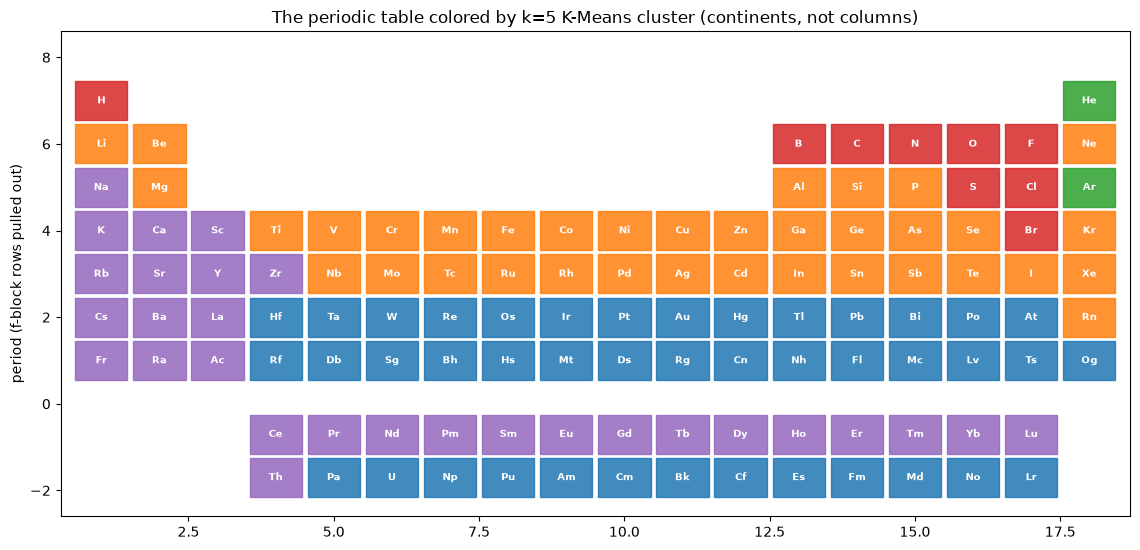

In [7]:
fig, ax = plt.subplots(figsize=(11.5, 5.6))
df_plot = df.assign(cluster=labels)
cmap = plt.get_cmap("tab10")
for _, r in df_plot.iterrows():
    if np.isfinite(r.group_id):
        xx, yy = r.group_id, 8 - r.period
    elif r.period == 6 and r.block == "f":
        xx, yy = 3 + (r.atomic_number - 57), -0.7
    else:
        xx, yy = 3 + (r.atomic_number - 89), -1.7
    ax.add_patch(plt.Rectangle((xx - 0.45, yy - 0.45), 0.9, 0.9,
                               color=cmap(int(r.cluster) % 10), alpha=0.85))
    ax.text(xx, yy, r.symbol, ha="center", va="center", fontsize=7.5,
            color="white", fontweight="bold")
ax.set_xlim(0.3, 18.7); ax.set_ylim(-2.6, 8.6)
ax.set_title(f"The periodic table colored by k={k_star} K-Means cluster (continents, not columns)")
ax.set_ylabel("period (f-block rows pulled out)")
plt.tight_layout(); plt.show()

import pathlib; pathlib.Path("reports/figures").mkdir(parents=True, exist_ok=True)
fig.savefig("reports/figures/f06_periodic_grid.png", dpi=150, bbox_inches="tight")


## Final statement (this is what the report keeps)

1. **ARI@k\* = 0.016 ± 0.000** (labeled 90): family **rediscovery fails** — and fails for a
   chemistry-legitimate reason: families are valence-configuration constructs, invisible to
   physical-property space (Li→Fr span argument).
2. **k=18 companion = 0.024**: forcing the family count does not manufacture families.
3. **Block battery 0.14–0.24**: weak coarse alignment — K-Means found the *continents*.
4. **H-sensitivity Δ −0.002**: our verdict does not hinge on one odd row.
5. **Unlabeled 28** landed in heavy-metal clusters ({13, 15}) — physically sensible, honestly reported.

Meta-lesson (the one Session 11 teaches here): **unsupervised ≠ magic**. Silhouette is honest
that the standardized cloud is a gradient (sil 0.36), so no k can carve a periodic family from
bulk properties — but the algorithm's failure IS structured. A negative result, correctly
explained, is a completed experiment.
